# Influx vs Non-influx: Exploratory Analysis

Load the processed daily dataset, compare influx and non-influx days across seven KNMI variables, estimate effect sizes and p-values, and summarize which weather variables separate the groups most in this dataset.

**Label definition:** The processed CSV was rebuilt using `n_records >= positive_counts.quantile(0.90)`. Below, compare top-5%, top-10%, and fixed `n_records >= 50` definitions. These are unusually high GBIF report counts, not directly measured bird abundance. A day with zero records does not establish that birds were absent, and reporting effort may affect counts. Statistical comparisons are exploratory, not causal or validated forecasting claims.

In [1]:
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display
from scipy.stats import mannwhitneyu

data_path = Path("data/processed/bird_predict_dataset.csv")
df = pd.read_csv(data_path, parse_dates=["date"])
stored_labels = df["influx"].copy()
features = ["DDVEC", "FG", "FHX", "TG", "TX", "PX", "RH"]
feature_units = {
    "DDVEC": "degrees (0 = calm/variable)",
    "FG": "0.1 m/s",
    "FHX": "0.1 m/s",
    "TG": "0.1 °C",
    "TX": "0.1 °C",
    "RH": "0.1 mm (-1 = trace, <0.05 mm)",
    "PX": "0.1 hPa",
}

df[["date", "n_records", "influx", *features]].head()

,date,n_records,influx,DDVEC,FG,FHX,TG,TX,PX,RH
0,2010-01-10,0,0,56,118,140,-1,4,10208,26
1,2010-01-11,0,0,65,60,90,-2,2,10209,-1
2,2010-01-12,0,0,99,58,90,-19,-1,10194,-1
3,2010-01-13,0,0,110,72,90,-36,-19,10081,2
4,2010-01-14,0,0,109,35,50,-5,12,10150,-1


## Dataset Profile

Check dataset size, date coverage, duplicate dates, missing values, and the origin of the current influx label before comparing groups.

In [2]:
calendar_gaps = (
    df["date"].sort_values().diff().dropna().ne(pd.Timedelta(days=1)).sum()
)
data_profile = pd.Series(
    {
        "Rows": len(df),
        "Columns": len(df.columns),
        "First date": df["date"].min().date(),
        "Last date": df["date"].max().date(),
        "Unique dates": df["date"].nunique(),
        "Duplicate dates": int(df["date"].duplicated().sum()),
        "Gaps in daily calendar": int(calendar_gaps),
        "Days with zero GBIF records": int(df["n_records"].eq(0).sum()),
        "Days with positive GBIF records": int(df["n_records"].gt(0).sum()),
    },
    name="value",
).to_frame()
missingness = df.isna().sum().rename("missing values").to_frame()
display(data_profile)
display(missingness)

positive_daily_counts = df.loc[df["n_records"] > 0, "n_records"]
label_threshold = positive_daily_counts.quantile(0.90)
df["influx"] = df["n_records"].ge(label_threshold).astype(int)
baseline_95_threshold = positive_daily_counts.quantile(0.95)
baseline_95_labels = df["n_records"].ge(baseline_95_threshold).astype(int)
minimum_influx_count = df.loc[df["influx"].eq(1), "n_records"].min()
labels_match_cutoff = df["influx"].eq(df["n_records"].ge(label_threshold).astype(int)).all()
stored_labels_match = stored_labels.eq(df["influx"]).all()
print(
    f"90th percentile label cutoff: {label_threshold:.1f}; "
    f"95th percentile baseline cutoff: {baseline_95_threshold:.1f}; "
    f"minimum influx-day count: {minimum_influx_count}; "
    f"regenerated labels match the 90th-percentile cutoff: {labels_match_cutoff}; "
    f"CSV labels match rebuilt labels: {stored_labels_match}."
)
print("KNMI source scaling:", feature_units)
print("RH = -1 represents trace precipitation (<0.05 mm); it is not a missing value.")
print("DDVEC is circular: arithmetic means/correlations near 0°/360° need careful interpretation.")

,value
Rows,6116
Columns,13
First date,2010-01-10
Last date,2026-10-08
Unique dates,6116
Duplicate dates,0
Gaps in daily calendar,0
Days with zero GBIF records,6033
Days with positive GBIF records,83


,missing values
STN,0
DATE,0
DDVEC,0
FG,0
FHX,0
TG,0
TN,0
TX,0
RH,0
PX,0


90th percentile label cutoff: 92.6; 95th percentile baseline cutoff: 153.8; minimum influx-day count: 95; regenerated labels match the 90th-percentile cutoff: True; CSV labels match rebuilt labels: True.
KNMI source scaling: {'DDVEC': 'degrees (0 = calm/variable)', 'FG': '0.1 m/s', 'FHX': '0.1 m/s', 'TG': '0.1 °C', 'TX': '0.1 °C', 'RH': '0.1 mm (-1 = trace, <0.05 mm)', 'PX': '0.1 hPa'}
RH = -1 represents trace precipitation (<0.05 mm); it is not a missing value.
DDVEC is circular: arithmetic means/correlations near 0°/360° need careful interpretation.


## Class Balance and Influx Dates
Review the label proportions and every date currently marked as an influx day.

In [3]:
class_balance = (
    df["influx"]
    .map({0: "Non-influx", 1: "Influx"})
    .value_counts()
    .rename_axis("class")
    .to_frame("days")
)
class_balance["share"] = class_balance["days"] / len(df)
class_balance

,days,share
class,,
Non-influx,6107,0.998528
Influx,9,0.001472


In [4]:
influx_dates = (
    df.loc[df["influx"].eq(1), ["date", "n_records"]]
    .sort_values(["n_records", "date"], ascending=[False, True])
)
display(influx_dates)
print("Top 20 positive-observation dates by n_records, including days below the influx cutoff:")
top_20_observation_dates = (
    df.loc[df["n_records"].gt(0), ["date", "n_records", "influx"]]
    .nlargest(20, "n_records")
    .sort_values(["n_records", "date"], ascending=[False, True])
)
top_20_observation_dates

,date,n_records
4674,2022-10-28,467
3942,2020-10-26,216
4673,2022-10-27,213
4675,2022-10-29,210
1392,2013-11-02,158
1385,2013-10-26,116
2128,2015-11-08,114
3943,2020-10-27,102
3941,2020-10-25,95


Top 20 positive-observation dates by n_records, including days below the influx cutoff:


,date,n_records,influx
4674,2022-10-28,467,1
3942,2020-10-26,216,1
4673,2022-10-27,213,1
4675,2022-10-29,210,1
1392,2013-11-02,158,1
1385,2013-10-26,116,1
2128,2015-11-08,114,1
3943,2020-10-27,102,1
3941,2020-10-25,95,1
4669,2022-10-23,83,0


## Daily Record Distribution
Counts are heavily concentrated at zero, so the histogram uses a logarithmic y-axis to make the positive-count tail visible.

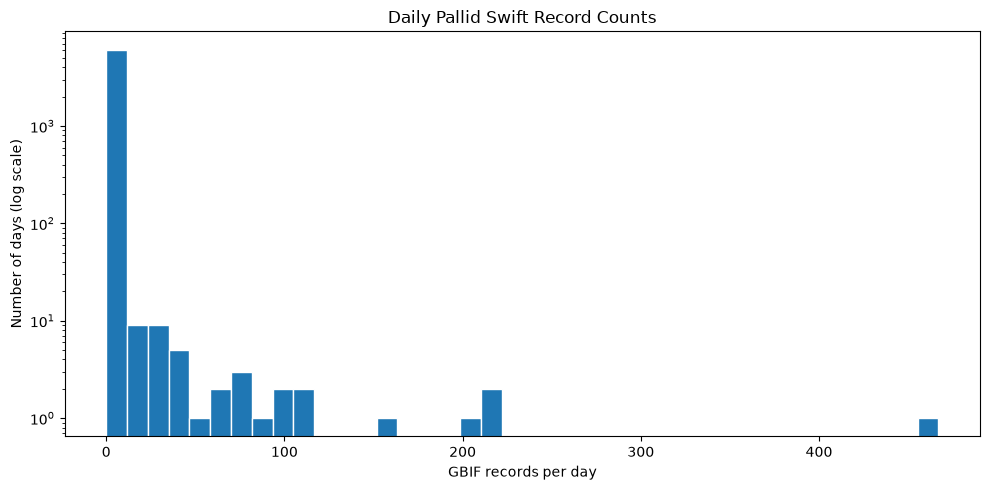

,n_records
count,6116.000000
mean,0.485448
std,8.829721
min,0.000000
50%,0.000000
75%,0.000000
90%,0.000000
95%,0.000000
99%,3.000000
max,467.000000


In [5]:
fig, ax = plt.subplots(figsize=(10, 5))
ax.hist(df["n_records"], bins=40, log=True, edgecolor="white")
ax.set_title("Daily Pallid Swift Record Counts")
ax.set_xlabel("GBIF records per day")
ax.set_ylabel("Number of days (log scale)")
plt.tight_layout()
plt.show()
record_count_statistics = df["n_records"].describe(
    percentiles=[0.50, 0.75, 0.90, 0.95, 0.99]
).to_frame("n_records")
record_count_statistics.loc["zero_count_days"] = df["n_records"].eq(0).sum()
record_count_statistics.loc["positive_count_days"] = df["n_records"].gt(0).sum()
record_count_statistics

## Weather Feature Comparison
Compare all eight KNMI weather fields between non-influx and influx days. Values retain KNMI's encoded source units; in particular, temperatures, wind speeds, precipitation, and pressure are scaled by 0.1, and `RH = -1` denotes trace precipitation.

In [6]:
comparison_rows = []
for feature in features:
    non_influx = df.loc[df["influx"].eq(0), feature]
    influx = df.loc[df["influx"].eq(1), feature]
    comparison_rows.append(
        {
            "feature": feature,
            "source_units": feature_units[feature],
            "non_influx_median": non_influx.median(),
            "non_influx_IQR": non_influx.quantile(0.75) - non_influx.quantile(0.25),
            "influx_median": influx.median(),
            "influx_min": influx.min(),
            "influx_max": influx.max(),
            "median_difference": influx.median() - non_influx.median(),
        }
    )
comparison = pd.DataFrame(comparison_rows).set_index("feature")
comparison

,source_units,non_influx_median,non_influx_IQR,influx_median,influx_min,influx_max,median_difference
feature,,,,,,,
DDVEC,degrees (0 = calm/variable),215.0,149.0,199.0,167,210,-16.0
FG,0.1 m/s,49.0,31.0,56.0,30,95,7.0
FHX,0.1 m/s,70.0,30.0,100.0,60,150,30.0
TG,0.1 °C,108.0,89.0,127.0,101,160,19.0
TX,0.1 °C,137.0,97.0,164.0,125,198,27.0
PX,0.1 hPa,10183.0,118.0,10077.0,9991,10268,-106.0
RH,"0.1 mm (-1 = trace, <0.05 mm)",1.0,23.0,7.0,-1,148,6.0


## Effect Sizes and Statistical Tests

For each feature, calculate Cliff's delta (equivalent to rank-biserial correlation here), where positive values mean larger values are more common on influx days. Test group differences with a two-sided Mann–Whitney U test and adjust the seven p-values with the Benjamini–Hochberg procedure. The p-values use the asymptotic approximation. Consecutive dates in the same weather/migration episode are not independent, so nominal p-values can be overconfident; this matters especially for permissive fixed thresholds. Treat tests as exploratory.

In [7]:
def calculate_effects(labels):
    effect_rows = []
    for feature in features:
        non_influx = df.loc[labels.eq(0), feature].dropna().to_numpy()
        influx = df.loc[labels.eq(1), feature].dropna().to_numpy()
        test = mannwhitneyu(influx, non_influx, alternative="two-sided", method="asymptotic")
        cliff_delta = 2 * test.statistic / (len(influx) * len(non_influx)) - 1
        effect_rows.append(
            {
                "feature": feature,
                "Cliffs_delta": cliff_delta,
                "absolute_delta": abs(cliff_delta),
                "median_difference": np.median(influx) - np.median(non_influx),
                "p_value": test.pvalue,
            }
        )

    result = pd.DataFrame(effect_rows).set_index("feature")
    p_values = result["p_value"].to_numpy()
    p_order = np.argsort(p_values)
    adjusted_sorted = np.minimum.accumulate(
        (p_values[p_order] * len(p_values) / np.arange(1, len(p_values) + 1))[::-1]
    )[::-1]
    adjusted_p_values = np.empty_like(adjusted_sorted)
    adjusted_p_values[p_order] = np.minimum(adjusted_sorted, 1)
    result["p_value_BH"] = adjusted_p_values
    return result.sort_values("absolute_delta", ascending=False)

fixed_50_labels = df["n_records"].ge(50).astype(int)
any_report_labels = df["n_records"].gt(0).astype(int)
label_definitions = {
    "Top 5% of positive days": baseline_95_labels,
    "Top 10% of positive days": df["influx"],
    "Fixed >= 50 reports/day": fixed_50_labels,
    "Fixed >= 25 reports/day": df["n_records"].ge(25).astype(int),
    "Fixed >= 10 reports/day": df["n_records"].ge(10).astype(int),
    "Any positive report day": any_report_labels,
}
def count_event_episodes(labels):
    event_dates = df.loc[labels.eq(1), "date"].sort_values()
    return int(event_dates.diff().dt.days.fillna(2).gt(1).sum())

definition_summary = pd.DataFrame(
    [
        {
            "definition": name,
            "threshold": (
                f">= {baseline_95_threshold:.1f}" if name.startswith("Top 5") else
                f">= {label_threshold:.1f}" if name.startswith("Top 10") else
                ">= 50" if "50" in name else
                ">= 25" if "25" in name else
                ">= 10" if "10" in name else "> 0"
            ),
            "influx_days": int(labels.sum()),
            "share_of_calendar": labels.mean(),
            "episodes_with_1_day_gap_rule": count_event_episodes(labels),
        }
        for name, labels in label_definitions.items()
    ]
).set_index("definition")
display(definition_summary)

effects = calculate_effects(df["influx"])
effects_95 = calculate_effects(baseline_95_labels)
effects_50 = calculate_effects(fixed_50_labels)
effects_25 = calculate_effects(label_definitions["Fixed >= 25 reports/day"])
effects_10 = calculate_effects(label_definitions["Fixed >= 10 reports/day"])
display(effects.round(6))

cutoff_comparison = pd.DataFrame(
    {
        "Cliffs_delta_95": effects_95["Cliffs_delta"],
        "p_value_95": effects_95["p_value"],
        "p_value_BH_95": effects_95["p_value_BH"],
        "Cliffs_delta_90": effects["Cliffs_delta"],
        "p_value_90": effects["p_value"],
        "p_value_BH_90": effects["p_value_BH"],
        "Cliffs_delta_fixed_50": effects_50["Cliffs_delta"],
        "p_value_fixed_50": effects_50["p_value"],
        "p_value_BH_fixed_50": effects_50["p_value_BH"],
        "Cliffs_delta_fixed_25": effects_25["Cliffs_delta"],
        "p_value_BH_fixed_25": effects_25["p_value_BH"],
        "Cliffs_delta_fixed_10": effects_10["Cliffs_delta"],
        "p_value_BH_fixed_10": effects_10["p_value_BH"],
    }
).sort_values("Cliffs_delta_90", key=lambda values: values.abs(), ascending=False)
display(cutoff_comparison.round(6))

print("Fixed >=50-report definition, ranked by absolute effect size:")
display(effects_50[["Cliffs_delta", "p_value", "p_value_BH"]].round(6))
print("Fixed >=10-report definition, ranked by absolute effect size:")
display(effects_10[["Cliffs_delta", "p_value", "p_value_BH"]].round(6))

print("Strongest observed univariate associations by |Cliff's delta|; exploratory, not causal or validated predictors:")
display(effects[["Cliffs_delta", "p_value", "p_value_BH"]].head(3).round(6))

,threshold,influx_days,share_of_calendar,episodes_with_1_day_gap_rule
definition,,,,
Top 5% of positive days,>= 153.8,5,0.000818,3
Top 10% of positive days,>= 92.6,9,0.001472,5
Fixed >= 50 reports/day,>= 50,16,0.002616,10
Fixed >= 25 reports/day,>= 25,30,0.004905,15
Fixed >= 10 reports/day,>= 10,45,0.007358,23
Any positive report day,> 0,83,0.013571,42


,Cliffs_delta,absolute_delta,median_difference,p_value,p_value_BH
feature,,,,,
FHX,0.490166,0.490166,30.0,0.010439,0.073073
PX,-0.349399,0.349399,-106.0,0.069684,0.243893
FG,0.252224,0.252224,7.0,0.190336,0.333497
TX,0.239125,0.239125,27.0,0.214446,0.333497
TG,0.227189,0.227189,19.0,0.238212,0.333497
DDVEC,-0.174827,0.174827,-16.0,0.364091,0.424773
RH,0.102269,0.102269,6.0,0.584638,0.584638


,Cliffs_delta_95,p_value_95,p_value_BH_95,Cliffs_delta_90,p_value_90,p_value_BH_90,Cliffs_delta_fixed_50,p_value_fixed_50,p_value_BH_fixed_50,Cliffs_delta_fixed_25,p_value_BH_fixed_25,Cliffs_delta_fixed_10,p_value_BH_fixed_10
feature,,,,,,,,,,,,,
FHX,0.299002,0.244152,0.543073,0.490166,0.010439,0.073073,0.357398,0.012836,0.044926,0.309218,0.011320,0.294672,0.002093
PX,-0.255605,0.322494,0.543073,-0.349399,0.069684,0.243893,-0.371127,0.010240,0.044926,-0.466420,0.000071,-0.449218,0.000001
FG,-0.046474,0.857311,0.857311,0.252224,0.190336,0.333497,0.251844,0.081414,0.113979,0.253292,0.038562,0.240535,0.012508
TX,0.303649,0.239859,0.543073,0.239125,0.214446,0.333497,0.268064,0.063658,0.112987,0.168540,0.129211,0.117941,0.172200
TG,0.273147,0.290391,0.543073,0.227189,0.238212,0.333497,0.267152,0.064564,0.112987,0.198866,0.104760,0.150566,0.113911
DDVEC,-0.223073,0.387909,0.543073,-0.174827,0.364091,0.424773,-0.129119,0.371721,0.371721,-0.181060,0.121322,-0.141071,0.119572
RH,-0.165079,0.510627,0.595731,0.102269,0.584638,0.584638,0.126926,0.365929,0.371721,0.138027,0.178687,0.201219,0.028833


Fixed >=50-report definition, ranked by absolute effect size:


,Cliffs_delta,p_value,p_value_BH
feature,,,
PX,-0.371127,0.010240,0.044926
FHX,0.357398,0.012836,0.044926
TX,0.268064,0.063658,0.112987
TG,0.267152,0.064564,0.112987
FG,0.251844,0.081414,0.113979
DDVEC,-0.129119,0.371721,0.371721
RH,0.126926,0.365929,0.371721


Fixed >=10-report definition, ranked by absolute effect size:


,Cliffs_delta,p_value,p_value_BH
feature,,,
PX,-0.449218,0.000000,0.000001
FHX,0.294672,0.000598,0.002093
FG,0.240535,0.005361,0.012508
RH,0.201219,0.016476,0.028833
TG,0.150566,0.081365,0.113911
DDVEC,-0.141071,0.102490,0.119572
TX,0.117941,0.172200,0.172200


Strongest observed univariate associations by |Cliff's delta|; exploratory, not causal or validated predictors:


,Cliffs_delta,p_value,p_value_BH
feature,,,
FHX,0.490166,0.010439,0.073073
PX,-0.349399,0.069684,0.243893
FG,0.252224,0.190336,0.333497


## Detailed Weather and Time Comparisons

Review distribution summaries and compare each weather feature on its own scale. The influx sample is very small, so these plots are descriptive rather than inferential.

count      mean     std     min      25%      50%  \
class      feature                                                       
Non-influx DDVEC    6107.0    192.87   93.14     1.0    111.0    215.0   
           FG       6107.0     53.66   23.72    10.0     36.0     49.0   
           FHX      6107.0     78.24   29.80    20.0     60.0     70.0   
           TG       6107.0    110.33   57.05  -114.0     69.0    108.0   
           TX       6107.0    139.36   63.21   -67.0     91.0    137.0   
           PX       6107.0  10178.32   94.65  9760.0  10122.0  10183.0   
           RH       6107.0     21.80   46.01    -1.0      0.0      1.0   
Influx     DDVEC       9.0    194.89   15.84   167.0    193.0    199.0   
           FG          9.0     61.67   20.78    30.0     45.0     56.0   
           FHX         9.0    103.33   28.28    60.0     90.0    100.0   
           TG          9.0    131.00   23.87   101.0    109.0    127.0   
           TX          9.0    162.22   28.57   125.0    132.0    164.0   
           PX          9.0  10108.11  109.69  9991.0  10011.0  10077.0   
           RH          9.0     31.89   51.24    -1.0      0.0      7.0   

                        75%      max  
class      feature                    
Non-influx DDVEC      260.0    360.0  
           FG          67.0    168.0  
           FHX         90.0    240.0  
           TG         158.0    287.0  
           TX         188.0    362.0  
           PX       10240.0  10470.0  
           RH          23.0    523.0  
Influx     DDVEC      205.0    210.0  
           FG          78.0     95.0  
           FHX        120.0    150.0  
           TG         154.0    160.0  
           TX         187.0    198.0  
           PX       10201.0  10268.0  
           RH          36.0    148.0

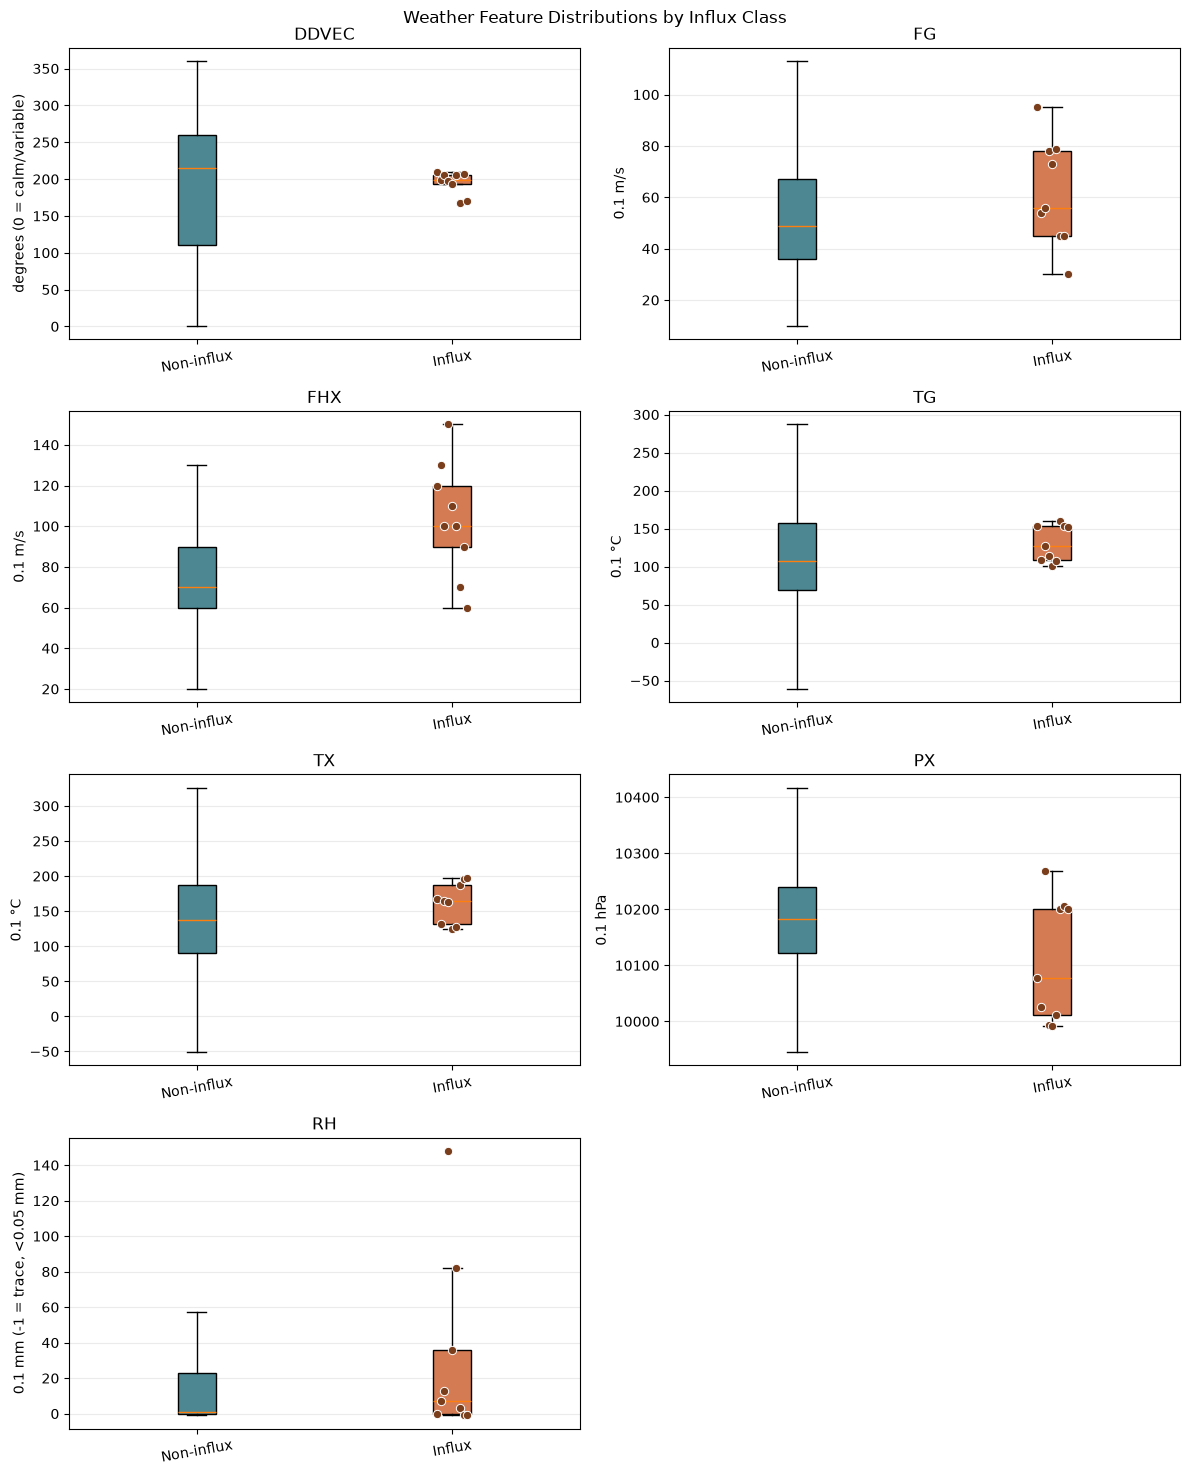

In [8]:
feature_summary = pd.concat(
    {
        "Non-influx": df.loc[df["influx"].eq(0), features].describe().T,
        "Influx": df.loc[df["influx"].eq(1), features].describe().T,
    },
    names=["class", "feature"],
).round(2)
display(feature_summary)

fig, axes = plt.subplots(4, 2, figsize=(12, 15))
class_groups = [
    df.loc[df["influx"].eq(0)],
    df.loc[df["influx"].eq(1)],
]
box_colors = ["#4c8792", "#d47b54"]
for feature, ax in zip(features, axes.flat):
    boxes = ax.boxplot(
        [group[feature] for group in class_groups],
        patch_artist=True,
        showfliers=False,
    )
    for box, color in zip(boxes["boxes"], box_colors):
        box.set_facecolor(color)
    ax.set_title(feature)
    ax.set_xticks([1, 2])
    ax.set_xticklabels(["Non-influx", "Influx"], rotation=10)
    influx_values = class_groups[1][feature].to_numpy()
    ax.scatter(
        2 + np.linspace(-0.06, 0.06, len(influx_values)),
        influx_values,
        color="#7a3e1d",
        edgecolor="white",
        linewidth=0.7,
        zorder=3,
    )
    ax.set_ylabel(feature_units[feature])
    ax.grid(axis="y", alpha=0.25)
axes.flat[-1].set_visible(False)
fig.suptitle("Weather Feature Distributions by Influx Class")
fig.tight_layout()
plt.show()

,days,influx_days,influx_rate
year,,,
2010,356,0,0.000000
2011,365,0,0.000000
2012,366,0,0.000000
2013,365,2,0.005479
2014,365,0,0.000000
2015,365,1,0.002740
2016,366,0,0.000000
2017,365,0,0.000000
2018,365,0,0.000000


,influx_days,observed_days,influx_rate
month,,,
1,0,518,0.000000
2,0,480,0.000000
3,0,527,0.000000
4,0,510,0.000000
5,0,527,0.000000
6,0,510,0.000000
7,0,527,0.000000
8,0,527,0.000000
9,0,510,0.000000


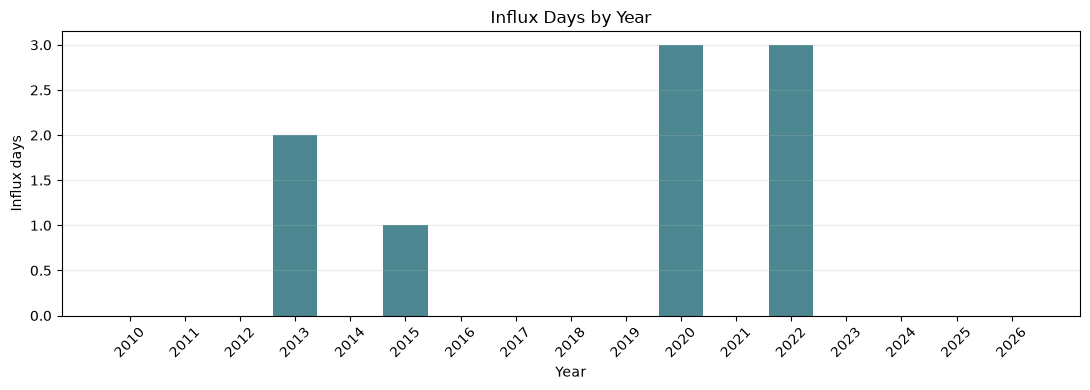

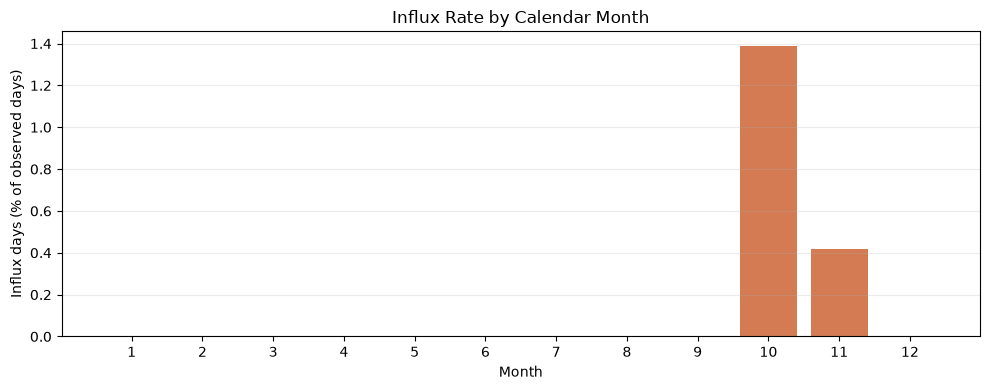

Pearson correlations with the binary influx label (DDVEC omitted because wind direction is circular):


,influx
FHX,0.032276
TG,0.013899
TX,0.013876
FG,0.012938
RH,0.008405
PX,-0.028420


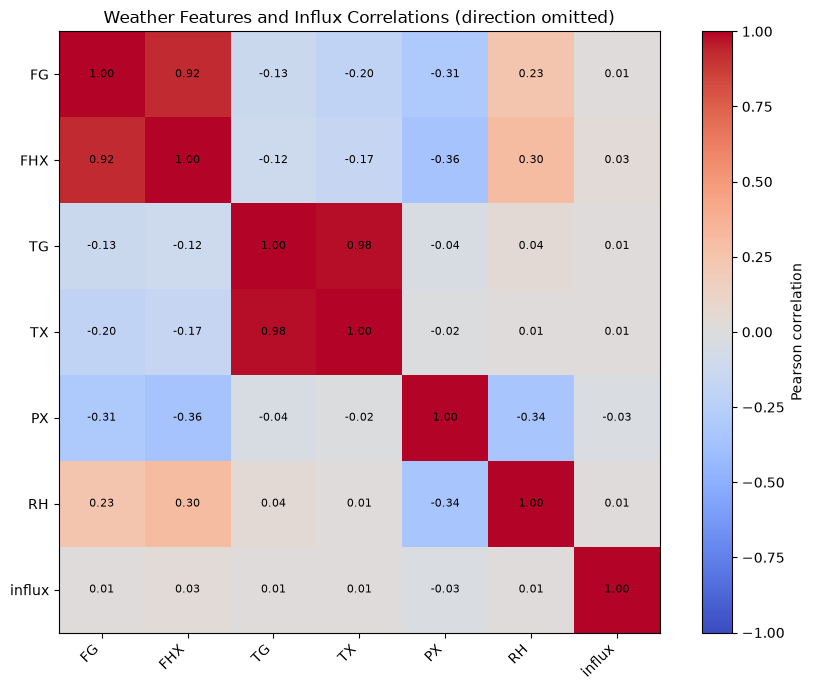

In [9]:
year_summary = (
    df.assign(year=df["date"].dt.year)
    .groupby("year")
    .agg(days=("influx", "size"), influx_days=("influx", "sum"))
)
year_summary["influx_rate"] = year_summary["influx_days"] / year_summary["days"]
display(year_summary)

monthly_influx_days = (
    df.loc[df["influx"].eq(1)]
    .groupby(df.loc[df["influx"].eq(1), "date"].dt.month)
    .size()
    .reindex(range(1, 13), fill_value=0)
    .rename("influx_days")
    .rename_axis("month")
    .to_frame()
)
monthly_influx_days["observed_days"] = df.groupby(df["date"].dt.month).size().reindex(range(1, 13), fill_value=0)
monthly_influx_days["influx_rate"] = monthly_influx_days["influx_days"] / monthly_influx_days["observed_days"]
display(monthly_influx_days)

fig, ax = plt.subplots(figsize=(11, 4))
ax.bar(year_summary.index, year_summary["influx_days"], color="#4c8792")
ax.set_title("Influx Days by Year")
ax.set_xlabel("Year")
ax.set_ylabel("Influx days")
ax.set_xticks(year_summary.index)
ax.tick_params(axis="x", rotation=45)
ax.grid(axis="y", alpha=0.25)
fig.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(10, 4))
ax.bar(monthly_influx_days.index, monthly_influx_days["influx_rate"] * 100, color="#d47b54")
ax.set_title("Influx Rate by Calendar Month")
ax.set_xlabel("Month")
ax.set_ylabel("Influx days (% of observed days)")
ax.set_xticks(range(1, 13))
ax.grid(axis="y", alpha=0.25)
fig.tight_layout()
plt.show()

correlation_features = [feature for feature in features if feature != "DDVEC"]
correlation = df[correlation_features + ["influx"]].corr()
print("Pearson correlations with the binary influx label (DDVEC omitted because wind direction is circular):")
display(correlation["influx"].drop("influx").sort_values(ascending=False).to_frame())

fig, ax = plt.subplots(figsize=(9, 7))
image = ax.imshow(correlation, cmap="coolwarm", vmin=-1, vmax=1)
labels = correlation.columns.tolist()
ax.set_xticks(range(len(labels)), labels=labels, rotation=45, ha="right")
ax.set_yticks(range(len(labels)), labels=labels)
for row in range(len(labels)):
    for column in range(len(labels)):
        ax.text(column, row, f"{correlation.iloc[row, column]:.2f}", ha="center", va="center", fontsize=8)
ax.set_title("Weather Features and Influx Correlations (direction omitted)")
fig.colorbar(image, ax=ax, label="Pearson correlation")
fig.tight_layout()
plt.show()

## Summary Report
The report below compares the original 95th-percentile cutoff with the regenerated 90th-percentile cutoff. Predictor strength refers to univariate effect size, not an independently validated forecasting model.

In [10]:
influx_count = int(df["influx"].eq(1).sum())
non_influx_count = int(df["influx"].eq(0).sum())
top_features = effects.head(3)
top_features_95 = effects_95.head(3)
top_features_10 = effects_10.head(3)
top_features_50 = effects_50.head(3)
significant_features = effects.loc[effects["p_value_BH"] < 0.05].index.tolist()
top_summary = ", ".join(top_features.index)
top_summary_95 = ", ".join(top_features_95.index)
top_summary_50 = ", ".join(top_features_50.index)
top_summary_10 = ", ".join(top_features_10.index)
significance_summary = ", ".join(significant_features) if significant_features else "none"
print(
    f"SUMMARY REPORT\n"
    f"Dataset: {len(df):,} consecutive daily observations from "
    f"{df['date'].min():%Y-%m-%d} through {df['date'].max():%Y-%m-%d}.\n"
    f"Class balance at 95th percentile: {int(baseline_95_labels.sum())} influx days; "
    f"at 90th percentile: {influx_count} influx days and {non_influx_count:,} non-influx days "
    f"({influx_count / len(df):.2%} influx).\n"
    f"A fixed >=50-report/day label gives {int(fixed_50_labels.sum())} days; "
    f">=25 gives {int(label_definitions['Fixed >= 25 reports/day'].sum())}; "
    f">=10 gives {int(label_definitions['Fixed >= 10 reports/day'].sum())}; "
    f"any positive report gives {int(any_report_labels.sum())} days.\n"
    f"Separated episodes (gap >1 day): >=50: {count_event_episodes(fixed_50_labels)}; "
    f">=10: {count_event_episodes(label_definitions['Fixed >= 10 reports/day'])}.\n"
    f"Top predictors by |Cliff's delta| at 95th percentile: {top_summary_95}.\n"
    f"Top predictors by |Cliff's delta| at 90th percentile: {top_summary}.\n"
    f"Top predictors by |Cliff's delta| at fixed >=50: {top_summary_50}.\n"
    f"Top predictors by |Cliff's delta| at fixed >=10: {top_summary_10}.\n"
    f"Features with 90th-percentile BH-adjusted p < 0.05: {significance_summary}.\n"
    "Interpretation: results are exploratory. With only a handful of influx days, "
    "effect sizes can be driven by individual dates and p-values have low power. "
    "Association does not establish causation or forecasting value."
)

SUMMARY REPORT
Dataset: 6,116 consecutive daily observations from 2010-01-10 through 2026-10-08.
Class balance at 95th percentile: 5 influx days; at 90th percentile: 9 influx days and 6,107 non-influx days (0.15% influx).
A fixed >=50-report/day label gives 16 days; >=25 gives 30; >=10 gives 45; any positive report gives 83 days.
Separated episodes (gap >1 day): >=50: 10; >=10: 23.
Top predictors by |Cliff's delta| at 95th percentile: TX, FHX, TG.
Top predictors by |Cliff's delta| at 90th percentile: FHX, PX, FG.
Top predictors by |Cliff's delta| at fixed >=50: PX, FHX, TX.
Top predictors by |Cliff's delta| at fixed >=10: PX, FHX, FG.
Features with 90th-percentile BH-adjusted p < 0.05: none.
Interpretation: results are exploratory. With only a handful of influx days, effect sizes can be driven by individual dates and p-values have low power. Association does not establish causation or forecasting value.


## Biological Interpretation and MVP Recommendation

The elevated-count dates cluster in October and November, which is consistent with an autumn passage/dispersal window at the northwestern edge of the Pallid Swift's usual range. A combination of seasonal movement and weather-assisted displacement is a reasonable biological hypothesis for rare Dutch records, but these observational data cannot distinguish migration, vagrancy, local weather effects, and changes in observer effort. In particular, the apparent association with stronger maximum wind (`FHX`) and lower pressure (`PX`) is a hypothesis for follow-up, not evidence that those conditions cause influxes. Weather measured at one KNMI station may not represent winds and conditions along a bird's route.

**Recommended target:** define operational high-report days as `n_records >= 50` (16 days) when measuring higher-confidence influx-like bursts. For a first exploratory supervised model, use `n_records >= 10` (45 days, about 23 separated runs using a one-day-gap rule) to avoid having fewer than 10 labels; this predicts report bursts, not confirmed biological influx. The looser cutoff may include routine passage and observer-effort variation. Keep raw counts and report both thresholds as sensitivity analyses. None of these definitions gives many independent events, so a dependable model is not yet supported. Collect standardized observation effort before treating zeros as true absences.

**Recommended predictors:** begin with `FHX`, `FG`, `PX`, `DDVEC`, and seasonal date. Transform `DDVEC` into sine/cosine components rather than using raw degrees. Consider one- to three-day lagged weather and weather anomalies relative to the same season, provided they are available at forecast time. Add `TG`, `TX`, and `RH` only after a larger sample supports the added complexity; do not use same-day GBIF counts as predictors.

**Validation and first model:** first compare a month/season-only climatology baseline with a strongly regularized logistic regression for the exploratory `>=10` target, limited initially to `FHX`, `PX`, and `FG` plus seasonal date. Use rolling-origin or leave-one-year-out validation, keeping entire migration seasons and multi-day episodes together; never randomly split days. Report precision-recall and event-level recall alongside calibration, and tune any probability cutoff using training years only. The `>=50` and 90th-percentile targets are even sparser (16 and 9 days). Prioritize more years and standardized observer effort before expanding to seven weather predictors or claiming reliable forecast skill. As a parallel MVP, model `n_records` as a count with an observation/effort component when available, rather than pretending unobserved days are confirmed absences.

**KNMI and label caveats:** wind and temperature values retain KNMI's tenths scaling; `RH = -1` denotes trace precipitation, not missing data. `DDVEC` is circular, so raw arithmetic comparisons around 0°/360° can mislead. KNMI cautions that this station series is inhomogeneous and unsuitable for long-term trend analysis. GBIF counts can reflect observer effort; a zero count does not demonstrate bird absence.